# Glucotrack Clustering — Member 1
## Clustering Track

**Dataset:** Diabetes Prediction Dataset - 100,000 records, 9 columns  
**Ground-truth label:** `diabetes` - used only for post-clustering interpretation  
**Algorithms:** K-Means and Agglomerative Hierarchical Clustering

This notebook follows the same structured style as the Regression notebook: numbered sections, clearly labelled code cells, printed checkpoints, EDA, preprocessing, model fitting, evaluation, plots, and observations.

**Important:** The `diabetes` column is excluded from all clustering features and model fitting. It is used only after clustering for interpretation and external validation.

**Member 1 scope:** dataset inspection, EDA, preprocessing, K-Means, and K-Means evaluation. Commit this first section to the shared `notebooks/clustering.ipynb` before your teammate continues.

## 1. Setup and Dataset Understanding

### 1.1 Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for plots, and scikit-learn/SciPy for clustering, evaluation, dimensionality reduction, and dendrograms.

In [1]:
# CELL 1: Setup & Imports

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.2 Load the dataset

The CSV is read from `../data/`, so the notebook runs from the project's `notebooks/` folder without changing paths.

In [2]:
# CELL 2: Load Dataset

DATA_PATH = "../data/diabetes_prediction_dataset.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place diabetes_prediction_dataset.csv inside the project's data folder."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("DATASET LOADING")
print("=" * 60)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Loaded from: {DATA_PATH}")
display(df.head())

DATASET LOADING
Dataset shape: 100,000 rows × 9 columns
Loaded from: ../data/diabetes_prediction_dataset.csv


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


### 1.3 Dataset structure

Inspect the column names and data types before deciding how to preprocess the features.

In [3]:
# CELL 3: Dataset Structure

print("=" * 60)
print("DATASET STRUCTURE")
print("=" * 60)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

DATASET STRUCTURE

Column names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types:


,Data Type
gender,str
age,float64
hypertension,int64
heart_disease,int64
smoking_history,str
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


### 1.4 Missing values and duplicates

Measure missing values and duplicate records before making any preprocessing decisions.

In [4]:
# CELL 4: Missing Value Analysis

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2)
})

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)
display(missing)

MISSING VALUE ANALYSIS


,Missing Values,Missing (%)
gender,0,0.0
age,0,0.0
hypertension,0,0.0
heart_disease,0,0.0
smoking_history,0,0.0
bmi,0,0.0
HbA1c_level,0,0.0
blood_glucose_level,0,0.0
diabetes,0,0.0


In [5]:
# CELL 5: Duplicate Record Analysis

duplicate_count = df.duplicated().sum()

print("=" * 60)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 60)
print(f"Duplicate rows: {duplicate_count:,}")
print(f"Duplicate percentage: {duplicate_count / len(df) * 100:.2f}%")

DUPLICATE RECORD ANALYSIS
Duplicate rows: 3,854
Duplicate percentage: 3.85%


### 1.5 Descriptive statistics

Review the distributions and scales of numeric columns.

In [6]:
# CELL 6: Descriptive Statistics

print("=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)
display(df.describe(include="all").T)

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,100000,3,Female,58552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,100000.0,NaN,NaN,NaN,41.885856,22.51684,0.08,24.0,43.0,60.0,80.0
hypertension,100000.0,NaN,NaN,NaN,0.07485,0.26315,0.0,0.0,0.0,0.0,1.0
heart_disease,100000.0,NaN,NaN,NaN,0.03942,0.194593,0.0,0.0,0.0,0.0,1.0
smoking_history,100000,6,No Info,35816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,100000.0,NaN,NaN,NaN,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,NaN,NaN,NaN,5.527507,1.070672,3.5,4.8,5.8,6.2,9.0
blood_glucose_level,100000.0,NaN,NaN,NaN,138.05806,40.708136,80.0,100.0,140.0,159.0,300.0
diabetes,100000.0,NaN,NaN,NaN,0.085,0.278883,0.0,0.0,0.0,0.0,1.0


### Observation - 1

After running the cells above, note the dataset size, any missing values, duplicates, and unusual value ranges. The notebook preserves the original rows for clustering; duplicate removal is not automatic because it changes the dataset population.

---

# 2. Exploratory Data Analysis

EDA is used to understand the dataset before clustering. The `diabetes` label is visualized only as a reference; it will not be included in the clustering input.

Ground-truth label counts (reference only):


,Count
diabetes,
0,91500
1,8500


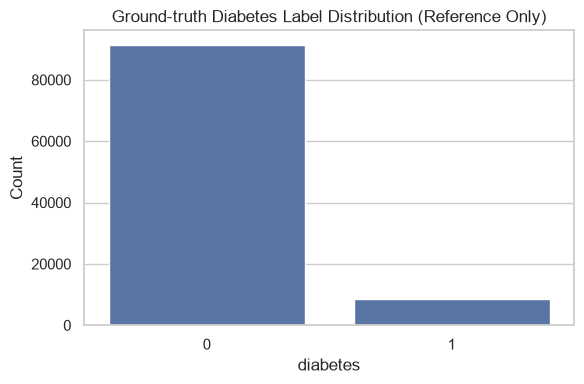

In [7]:
# CELL 7: Target Distribution (Reference Only)

if "diabetes" not in df.columns:
    raise ValueError("The expected 'diabetes' column was not found.")

print("Ground-truth label counts (reference only):")
display(df["diabetes"].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="diabetes")
plt.title("Ground-truth Diabetes Label Distribution (Reference Only)")
plt.xlabel("diabetes")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [8]:
# CELL 8: Categorical Feature Analysis

categorical_columns = df.drop(columns=["diabetes"]).select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical feature columns:", categorical_columns)

for col in categorical_columns:
    print(f"\nValue counts for {col}:")
    display(df[col].value_counts(dropna=False).to_frame("Count"))

Categorical feature columns: ['gender', 'smoking_history']

Value counts for gender:


,Count
gender,
Female,58552
Male,41430
Other,18



Value counts for smoking_history:


,Count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


Numeric feature columns: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']


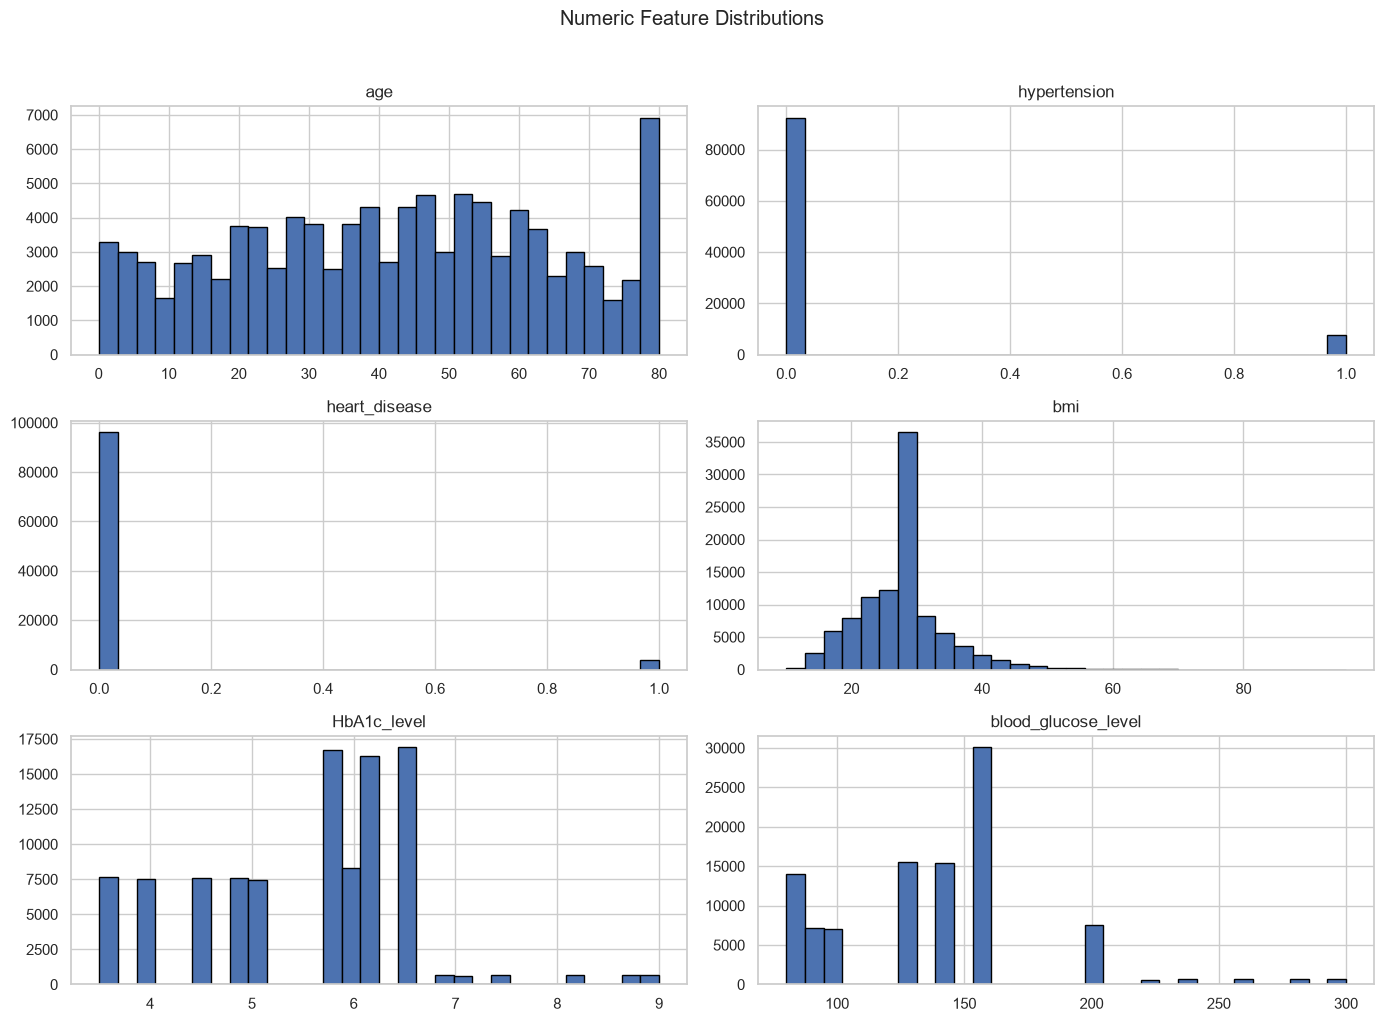

In [9]:
# CELL 9: Numeric Feature Distributions

numeric_columns = df.drop(columns=["diabetes"]).select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric feature columns:", numeric_columns)

df[numeric_columns].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

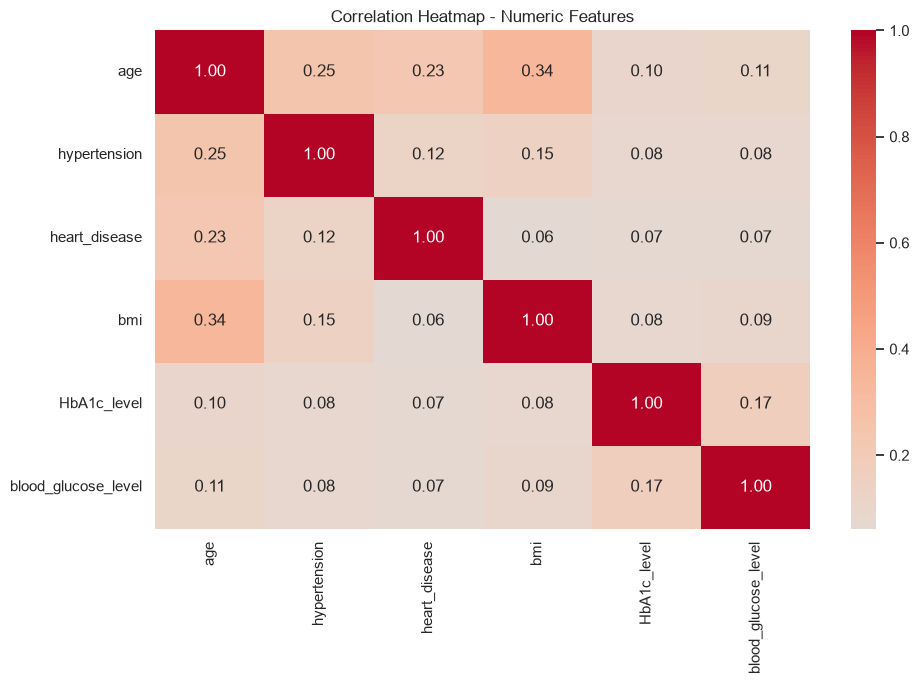

In [10]:
# CELL 10: Correlation Heatmap for Numeric Features

if len(numeric_columns) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        df[numeric_columns].corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Heatmap - Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

### Observation - 2

Write down the main patterns you notice from the distributions and correlation heatmap. These plots describe the input features; they do not determine cluster labels.

---

# 3. Data Preprocessing

The target column is separated before preprocessing. Numeric features are median-imputed and standardized; categorical features are imputed with the most frequent value and one-hot encoded. The resulting feature matrix is used for all clustering algorithms.

In [11]:
# CELL 11: Separate Features and Ground-Truth Label

if "diabetes" not in df.columns:
    raise ValueError("Expected target column 'diabetes' was not found.")

y_true = df["diabetes"].copy()        # Reserved for post-hoc interpretation only
X_raw = df.drop(columns=["diabetes"]).copy()

numeric_features = X_raw.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_raw.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Feature matrix shape before preprocessing:", X_raw.shape)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target excluded from X:", "diabetes" not in X_raw.columns)

Feature matrix shape before preprocessing: (100000, 8)
Numeric features: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level']
Categorical features: ['gender', 'smoking_history']
Target excluded from X: True


In [12]:
# CELL 12: Build Preprocessing Pipeline

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [13]:
# CELL 13: Transform Features

X_processed = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()
X_processed = np.asarray(X_processed, dtype=np.float32)

print("=" * 60)
print("PREPROCESSING COMPLETE")
print("=" * 60)
print("Processed matrix shape:", X_processed.shape)
print("Number of transformed features:", len(feature_names))
print("Contains only feature columns (no diabetes target):", "diabetes" not in list(X_raw.columns))

PREPROCESSING COMPLETE
Processed matrix shape: (100000, 15)
Number of transformed features: 15
Contains only feature columns (no diabetes target): True


### Observation - 3

Standardization is important for distance-based clustering because numeric features with large scales can otherwise dominate distances. One-hot encoding converts categorical values into numeric indicators.

---

# 4. K-Means Clustering

K-Means groups observations around cluster centroids. The Elbow Method examines how inertia changes as the number of clusters increases.

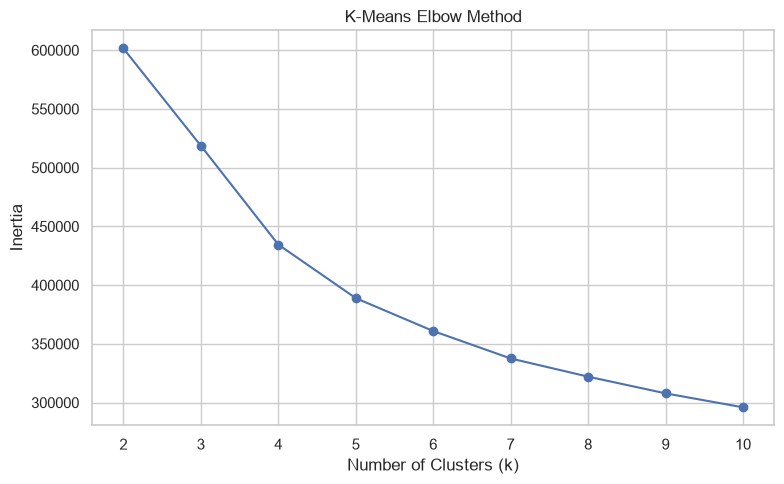

,k,Inertia
0,2,601527.56
1,3,518679.19
2,4,434536.44
3,5,388926.00
4,6,360908.88
5,7,337557.00
6,8,322069.41
7,9,307848.25
8,10,295954.47


In [14]:
# CELL 14: Elbow Method

MAX_K = 10
k_values = list(range(2, MAX_K + 1))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_processed)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.tight_layout()
plt.show()

elbow_results = pd.DataFrame({"k": k_values, "Inertia": inertias})
display(elbow_results.round(2))

### 4.1 Select the number of clusters

Review the Elbow plot and choose a value for `BEST_K`. The default below is 3 as a starting point; change it if your plot supports a different choice. The elbow is a heuristic, not a guaranteed optimum.

In [15]:
# CELL 15: Fit K-Means

BEST_K = 3  # Change this after reviewing the Elbow plot

kmeans_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)
kmeans_labels = kmeans_model.fit_predict(X_processed)

print(f"K-Means fitted with k={BEST_K}.")
print("\nCluster sizes:")
display(pd.Series(kmeans_labels, name="Cluster").value_counts().sort_index().to_frame("Count"))

K-Means fitted with k=3.

Cluster sizes:


,Count
Cluster,
0,50567
1,45491
2,3942


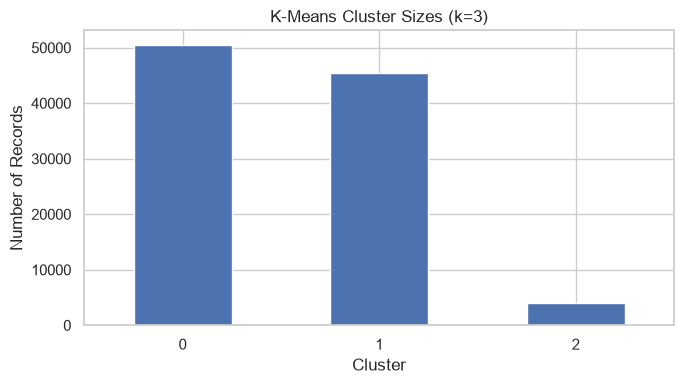

In [16]:
# CELL 16: K-Means Cluster Size Plot

cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()

plt.figure(figsize=(7, 4))
cluster_counts.plot(kind="bar")
plt.title(f"K-Means Cluster Sizes (k={BEST_K})")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation - 4

Record the chosen value of K and explain whether the Elbow plot has a clear bend or a gradual decline.

---

# 5. Clustering Evaluation Metrics

All clustering algorithms are evaluated using:
- **Silhouette Score:** higher values generally indicate better separation.
- **Davies–Bouldin Index:** lower values generally indicate more compact, separated clusters.
- **Calinski–Harabasz Index:** higher values generally indicate better-defined clusters.

For very large datasets, metrics are calculated on a reproducible sample to control computation time.

In [17]:
# CELL 17: Evaluation Function

def evaluate_clustering(X, labels, algorithm_name, sample_size=10000, random_state=RANDOM_STATE):
    labels = np.asarray(labels)
    unique_labels = np.unique(labels)

    if len(unique_labels) < 2 or len(unique_labels) >= len(labels):
        return {
            "Algorithm": algorithm_name,
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    if len(labels) > sample_size:
        rng = np.random.default_rng(random_state)
        indices = rng.choice(len(labels), size=sample_size, replace=False)
        X_eval = X[indices]
        labels_eval = labels[indices]
    else:
        X_eval = X
        labels_eval = labels

    if len(np.unique(labels_eval)) < 2:
        return {
            "Algorithm": algorithm_name,
            "Silhouette Score": np.nan,
            "Davies-Bouldin Index": np.nan,
            "Calinski-Harabasz Index": np.nan
        }

    return {
        "Algorithm": algorithm_name,
        "Silhouette Score": silhouette_score(X_eval, labels_eval),
        "Davies-Bouldin Index": davies_bouldin_score(X_eval, labels_eval),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_eval, labels_eval)
    }

print("Evaluation function defined.")

Evaluation function defined.


In [18]:
# CELL 18: Evaluate K-Means

kmeans_metrics = evaluate_clustering(
    X_processed,
    kmeans_labels,
    f"K-Means (k={BEST_K})"
)

kmeans_metrics_df = pd.DataFrame([kmeans_metrics])
display(kmeans_metrics_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (k=3),0.1588,1.7414,2014.4672


### Observation - 5

Use all three metrics together rather than choosing a model from one metric alone. Silhouette values can be low for overlapping real-world data and should be interpreted in context.